# NicheJEPA Tutorial

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 30.06.2025
- Date of Last Modification: 30.06.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import warnings

import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline)
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/lotfollahi/sb75/nichejepa-reproducibility/artifacts'
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055'

### 1.3 Define Config

In [5]:
min_cells_per_niche = 100
latent_cluster_key = 'predicted_niche'

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
#sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
#os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Analysis

### 2.1 xhk1007-CV1-41b_1p (Xenium Human Kidney)

In [11]:
dataset_name = 'xhk1007-CV1-41b_1p'
cell_type_key = 'level_1_cell_type'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-2.h5ad'

#### 2.1.1 Load Data

In [12]:
adata = sc.read_h5ad(file_path)

/tmp/ipykernel_1511852/3623556005.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata,


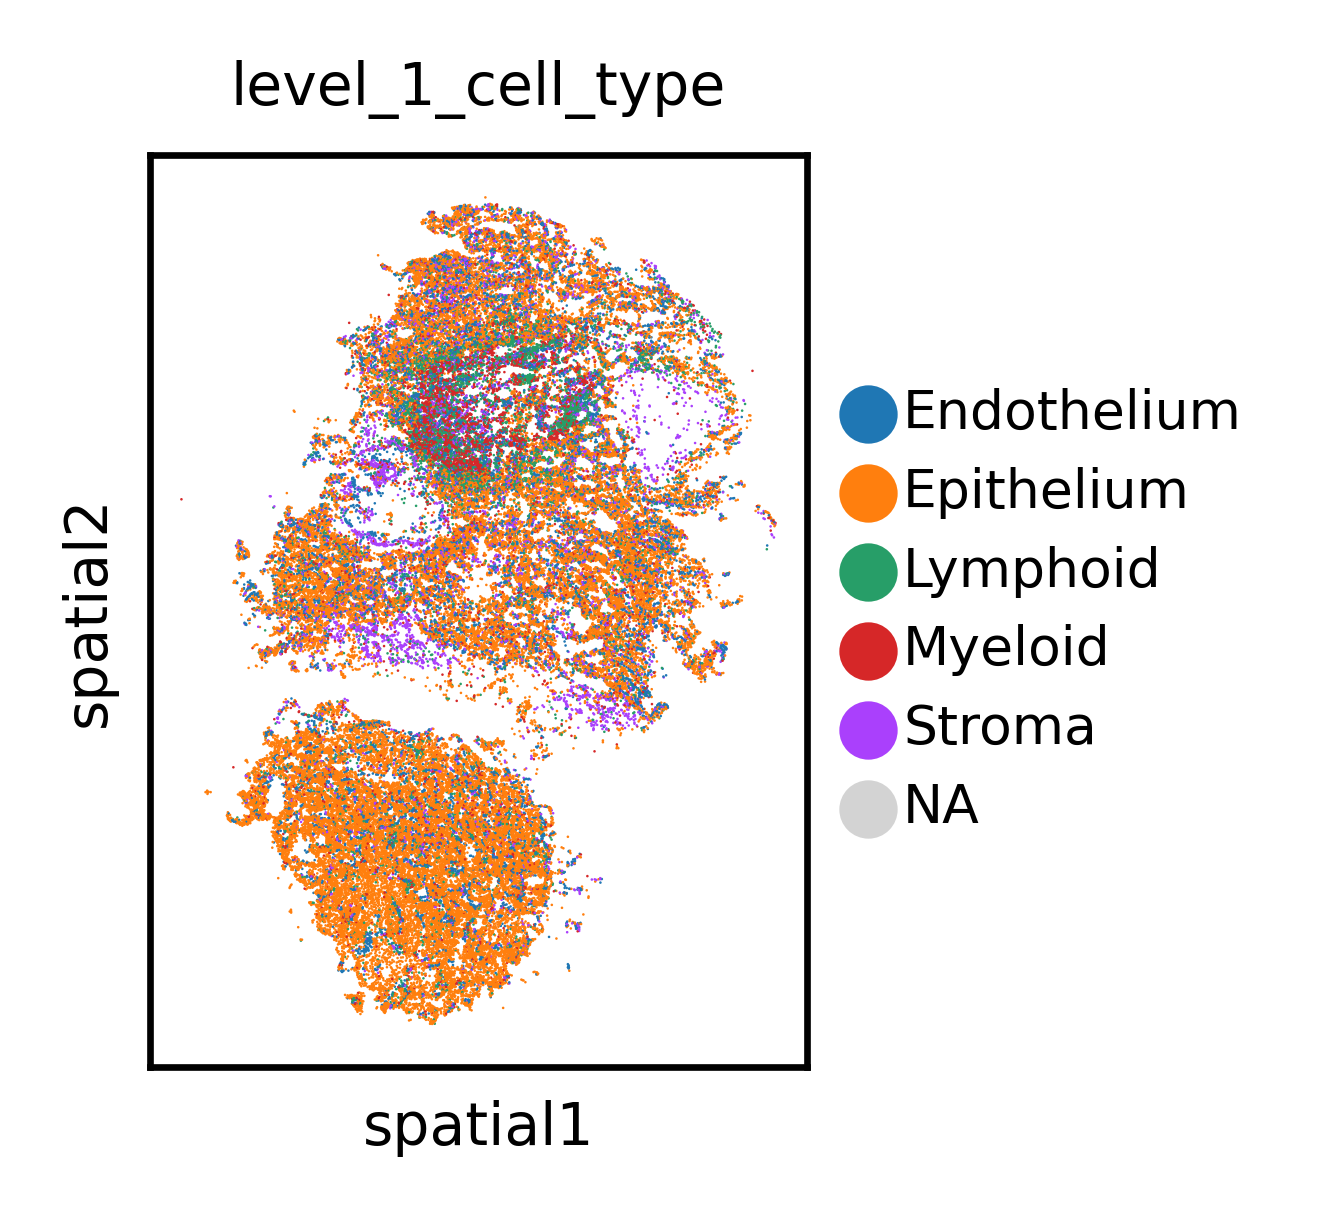

In [13]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color=cell_type_key)

#### 2.1.2 Harmonize Data

In [14]:
adata = harmonize_adata(adata)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4949.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


#### 2.1.3 Tokenize Data

In [15]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/sb75/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...
Map (num_proc=4): 100%|██████████| 71118/71118 [13:29<00:00, 87.88 examples/s]   


#### 2.1.4 Embed Data

In [ ]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
cell_gene_ids = []
neighborhood_gene_ids = []

In [ ]:
output_embed = embed_dataset(
    dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['cell_emb'] = output_embed['cell_emb']
adata.obsm['neighborhood_emb'] = output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell',
           key_added='cell_umap')
adata.obsm['X_umap'] = adata.obsm['cell_umap']
sc.pl.umap(adata,
           neighbors_key='cell',
           color=label)

#### 2.1.5 Perturbed Data

In [ ]:
# Define perturbations
perturbed_cell_id = ['1007_batch20_0', '1007_batch20_0', '1007_batch20_1']
perturbed_ensembl_id = ['all', 'all', 'ENSG00000169194'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'foldchange'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, 0.5] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

In [ ]:
perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path)

#### 2.1.6 Embed Perturb Data

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth - 8)
latent_leiden_resolution = 0.2

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata_test = sc.read_h5ad(f'/nfs/team361/dj17/inflow_pertubation/adata_unperturbed_v2.h5ad')
adata_test.obs['cell_id']

# Initialize the column with False
adata.obs['selected'] = False

# Set True for the selected indices
adata.obs.loc[adata.obs.index[selected_indices], 'selected'] = True